# One trading day by hand

This notebook goes through the whole pipeline for a single trading day: features, label, model, portfolio, turnover, spread estimate, costs and the holding buffer. Each step is first computed by hand and then compared with the function in `src/` that the backtest uses.

The data are **synthetic**. The CRSP data used in the project cannot be shared, so I simulate 20 stocks with known bid-ask spreads. With 20 stocks, the portfolio holds k = 3 stocks per side instead of 10.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))  
from src.config import load_config
from src.features import to_wide, study_periods, period_dataset
from src.models import gbt_probability, reversal_score
from src.backtest import portfolio_weights, long_short_returns, buffer_weights
from src.costs import two_day_spread, rolling_spread, turnover, spread_costs

cfg = load_config()
pd.set_option("display.precision", 4)

## 1. Synthetic prices

Each stock has an efficient price that follows a random walk with 2 % daily volatility. During the day there are 390 trades, and each trade happens at the ask or at the bid, i.e., at the efficient price times $1 \pm S/2$, where $S$ is the stock's true spread (5 to 60 bps). The daily high, low and close are the highest, lowest and last trade.

So that the model has something to learn, the overnight move partly reverses the previous day's move of the efficient price (coefficient $-0.05$). On top of that, closing at the bid or the ask creates a bid-ask bounce in the close-to-close returns.

In [2]:
rng = np.random.default_rng(cfg["seed"])
n_stocks, n_days, n_trades = 20, 1002, 390
true_spread = np.linspace(0.0005, 0.006, n_stocks) # 5 to 60 bps
ids = [f"S{i + 1:02d}" for i in range(n_stocks)]
dates = pd.bdate_range("2015-01-02", periods=n_days)

log_open = np.zeros((n_days, n_stocks))
log_eff = np.zeros((n_days, n_trades, n_stocks))
prev_move = np.zeros(n_stocks)
level = np.log(50.0) * np.ones(n_stocks)
for t in range(n_days):
    level = level + rng.normal(0, 0.005, n_stocks) - 0.05 * prev_move    # overnight move with reversal
    path = level + np.cumsum(rng.normal(0, 0.02 / np.sqrt(n_trades), (n_trades, n_stocks)), axis=0)
    log_eff[t] = path
    prev_move = path[-1] - (level if t == 0 else log_eff[t - 1, -1])
    level = path[-1]

side = rng.choice([-1, 1], size=log_eff.shape)
trade_price = np.exp(log_eff) * (1 + side * true_spread / 2)

panel = pd.DataFrame({
    "date": np.repeat(dates, n_stocks),
    "id": np.tile(ids, n_days),
    "open": trade_price[:, 0].ravel(),
    "high": trade_price.max(axis=1).ravel(),
    "low": trade_price.min(axis=1).ravel(),
    "close": trade_price[:, -1].ravel(),
})
panel = panel.sort_values(["id", "date"]).reset_index(drop=True)
panel["ret"] = panel.groupby("id")["close"].pct_change()
panel["cumfacpr"] = 1.0          # no splits
panel["in_sp500"] = True         # all 20 stocks are in the universe on every day
print(panel.shape, panel["date"].min().date(), panel["date"].max().date())
panel.head()

(20040, 9) 2015-01-02 2018-11-05


,date,id,open,high,low,close,ret,cumfacpr,in_sp500
0,2015-01-02,S01,50.0794,51.0484,49.5980,50.6664,NaN,1.0,True
1,2015-01-05,S01,50.6662,50.6662,49.0618,49.3690,-0.0256,1.0,True
2,2015-01-06,S01,49.3504,51.3087,49.1065,51.2530,0.0382,1.0,True
3,2015-01-07,S01,51.6892,52.7322,50.8640,51.4004,0.0029,1.0,True
4,2015-01-08,S01,51.8257,52.1047,51.0552,51.4656,0.0013,1.0,True


## 2. Features and label

As in the paper, the sample is cut into a study period of 1000 days: 750 for training and 250 for trading. For stock $s$ on day $t$ the features are the returns over the last $m$ days,
$$R^s_{t,m} = \prod_{j=t-m+1}^{t} (1 + r^s_j) - 1, \qquad m \in \{1,\dots,20\} \cup \{40, 60, \dots, 240\},$$
and the label is 1 if the stock's return on day $t+1$ is strictly above the median of the day.

I pick one trading day $t$ and compute some features of the first stock by hand.

In [3]:
ret_wide, member_wide = to_wide(panel)
period = study_periods(len(ret_wide), cfg["study_periods"]["train_days"], cfg["study_periods"]["trade_days"])[0]
features = [f"R{m}" for m in cfg["features"]["horizons"]]
train, trade = period_dataset(ret_wide, member_wide, period, cfg["features"]["horizons"])

trade_days = trade["date"].unique()
t, t_prev = trade_days[100], trade_days[99]
day = trade[trade["date"] == t].set_index("id")
print("training rows:", len(train), " trading rows:", len(trade), " day t:", pd.Timestamp(t).date())

# features of stock S01 on day t by hand: compound the last m daily returns
r = ret_wide["S01"].loc[:t]
for m in [1, 5, 20, 240]:
    print(f"R{m}: by hand {np.prod(1 + r.iloc[-m:]) - 1:+.5f}   pipeline {day.loc['S01', f'R{m}']:+.5f}")

training rows: 10200  trading rows: 5000  day t: 2018-04-06
R1: by hand -0.01772   pipeline -0.01772
R5: by hand +0.00824   pipeline +0.00824
R20: by hand +0.04100   pipeline +0.04100
R240: by hand +0.40544   pipeline +0.40544


In [4]:
# label by hand: compare each stock's return on day t+1 with the median of the day
median = day["ret_t1"].median()
by_hand = (day["ret_t1"] > median).astype(float)
print(f"median return on day t+1: {median:+.4%}")
print("labels agree with the pipeline:", (by_hand == day["y"]).all(), "| share of ones:", by_hand.mean())

median return on day t+1: -0.1737%
labels agree with the pipeline: True | share of ones: 0.5


## 3. Signal

The gradient-boosted trees (LightGBM, settings from the paper) are trained on the 510 training days that remain after the 240-day look-back and predict $\hat p = \mathbb{P}(y = 1)$ for every stock on the trading days. The reversal benchmark simply uses minus the last day's return as score.

In [5]:
trade["prob"] = gbt_probability(train, trade, features, cfg["model"], cfg["seed"])
trade["reversal"] = reversal_score(trade)
day = trade[trade["date"] == t].set_index("id")
day[["R1", "R5", "prob", "reversal", "ret_t1"]].sort_values("prob", ascending=False)

,R1,R5,prob,reversal,ret_t1
id,,,,,
S10,-0.0431,-0.0793,0.5518,0.0431,0.0115
S19,0.0063,0.0059,0.5423,-0.0063,0.0217
S05,-0.0125,0.0044,0.5331,0.0125,-0.0008
S04,0.0033,0.0102,0.5318,-0.0033,-0.0127
S20,-0.0225,0.0300,0.5276,0.0225,-0.0012
S15,-0.0056,0.0669,0.5239,0.0056,-0.0233
S01,-0.0177,0.0082,0.5232,0.0177,-0.0106
S02,0.0061,-0.0129,0.5146,-0.0061,0.0070
S08,0.0215,0.0801,0.5021,-0.0215,-0.0081


## 4. Portfolio and gross return

On day $t$ the strategy buys the three stocks with the highest probability and sells the three with the lowest, each with weight $1/3$. With lag 0 (as in the paper), the portfolio is formed at the close of day $t$ and earns the return of day $t+1$:
$$r^{LS}_{t+1} = \tfrac{1}{k} \sum_{\text{long}} r^s_{t+1} - \tfrac{1}{k} \sum_{\text{short}} r^s_{t+1}.$$

In [6]:
k = 3
ranked = day.sort_values("prob", ascending=False)
long, short = ranked.index[:k], ranked.index[-k:]
gross = ranked.loc[long, "ret_t1"].mean() - ranked.loc[short, "ret_t1"].mean()

print("long: ", list(long), " short:", list(short))
print(f"gross return by hand: {gross:+.4%}")
print(f"pipeline:             {long_short_returns(trade, 'prob', k).loc[t]:+.4%}")

long:  ['S10', 'S19', 'S05']  short: ['S16', 'S17', 'S13']
gross return by hand: +2.7046%
pipeline:             +2.7046%


## 5. Turnover

The turnover of day $t$ is $\sum_i |w_{i,t} - w_{i,t-1}|$. A stock that stays in the same leg costs nothing; a stock that is replaced is traded twice (sold and bought). Replacing the whole portfolio gives a turnover of 4.

In [7]:
weights = portfolio_weights(trade, "prob", k)
w = pd.DataFrame({"w_prev": weights.loc[t_prev], "w_t": weights.loc[t]})
w["traded"] = (w["w_t"] - w["w_prev"]).abs()
w = w[(w["w_prev"] != 0) | (w["w_t"] != 0)]
print(w)
print(f"\nturnover by hand: {w['traded'].sum():.4f}   pipeline: {turnover(weights).loc[t]:.4f}")

     w_prev     w_t  traded
id                         
S04  0.3333  0.0000  0.3333
S05  0.0000  0.3333  0.3333
S06  0.3333  0.0000  0.3333
S10  0.0000  0.3333  0.3333
S11  0.3333  0.0000  0.3333
S13 -0.3333 -0.3333  0.0000
S16 -0.3333 -0.3333  0.0000
S17  0.0000 -0.3333  0.3333
S18 -0.3333  0.0000  0.3333
S19  0.0000  0.3333  0.3333

turnover by hand: 2.6667   pipeline: 2.6667


## 6. Corwin-Schultz spread estimate

The high-low range of a day contains the volatility of the efficient price and the spread. Volatility grows with time, the spread does not: the range over two days contains the spread only once. With $\beta$ the sum of the two squared one-day log ranges and $\gamma$ the squared two-day log range,
$$\alpha = \frac{\sqrt{2\beta} - \sqrt{\beta}}{3 - 2\sqrt 2} - \sqrt{\frac{\gamma}{3 - 2\sqrt 2}}, \qquad S = \frac{2(e^\alpha - 1)}{1 + e^\alpha}.$$
Before that, an overnight jump is removed from the prices of day $t$. I compute the estimate for one stock that the portfolio trades on day $t$.

In [8]:
stock = w.index[w["traded"] > 0][0]
p = panel[panel["id"] == stock].set_index("date")
H0, L0, C0 = p.loc[t_prev, ["high", "low", "close"]]
H1, L1 = p.loc[t, ["high", "low"]]

# overnight adjustment: shift day t so that it touches the previous close
gap = L1 - C0 if L1 > C0 else (H1 - C0 if H1 < C0 else 0.0)
H1a, L1a = H1 - gap, L1 - gap

beta = np.log(H0 / L0) ** 2 + np.log(H1a / L1a) ** 2
gamma = np.log(max(H0, H1a) / min(L0, L1a)) ** 2
c = 3 - 2 * np.sqrt(2)
alpha = (np.sqrt(2 * beta) - np.sqrt(beta)) / c - np.sqrt(gamma / c)
S = 2 * (np.exp(alpha) - 1) / (1 + np.exp(alpha))

print(f"stock {stock}: beta {beta:.6f}, gamma {gamma:.6f}, alpha {alpha:+.6f}")
print(f"two-day estimate by hand: {S:+.4%}   pipeline: "
      f"{two_day_spread(np.array([H0]), np.array([L0]), np.array([H1]), np.array([L1]), np.array([C0]))[0]:+.4%}")
print(f"true spread: {true_spread[ids.index(stock)]:.4%}")

stock S04: beta 0.002541, gamma 0.002162, alpha +0.009437
two-day estimate by hand: +0.9437%   pipeline: +0.9437%
true spread: 0.1368%


A single two-day estimate is very noisy and can be negative. The pipeline therefore averages the last 21 two-day estimates and floors only the average, at one tick (one cent) relative to the closing price.

In [9]:
spreads = rolling_spread(panel, cfg["costs"]["spread_window"], cfg["costs"]["spread_min_obs"],
                         cfg["costs"]["tick_sizes"])
s = spreads[spreads["id"] == stock].set_index("date")
last21 = s.loc[:t, "raw"].iloc[-21:]
floor = 0.01 / p.loc[t, "close"]
print(f"mean of the last 21 two-day estimates: {last21.mean():.4%}, tick floor {floor:.4%}")
print(f"estimate by hand: {max(last21.mean(), floor):.4%}   pipeline: {s.loc[t, 'spread']:.4%}")

mean of the last 21 two-day estimates: 0.4236%, tick floor 0.0203%
estimate by hand: 0.4236%   pipeline: 0.4236%


Averaged over the whole sample, the estimates line up with the true spreads, but not perfectly. For the stocks with small spreads they are clearly too high (around 20 bps instead of 5 to 15 bps): with 2 % daily volatility, the range is dominated by price moves, and small errors in separating volatility from the spread are large compared with the spread itself. This is the same reason why, in the real data, the estimates for volatile stocks with small spreads are probably too high.

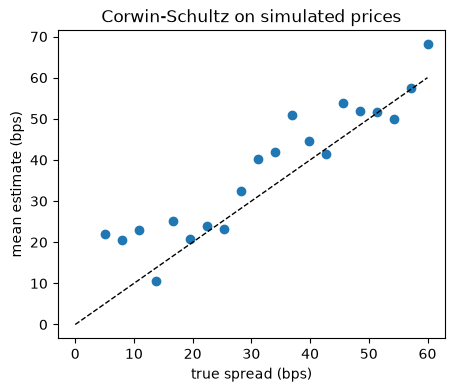

In [10]:
check = spreads.groupby("id")["unfloored"].mean().to_frame("estimated")
check["true"] = true_spread
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(check["true"] * 1e4, check["estimated"] * 1e4)
ax.plot([0, 60], [0, 60], "k--", lw=1)
ax.set_xlabel("true spread (bps)")
ax.set_ylabel("mean estimate (bps)")
ax.set_title("Corwin-Schultz on simulated prices")
plt.show()

## 7. Costs and net return

Each unit traded costs half the spread (buying at the ask, selling at the bid, both half a spread away from the midpoint). The costs of day $t$ are $\sum_i \frac{\hat S_{i,t}}{2} |w_{i,t} - w_{i,t-1}|$. The paper instead charges a flat 5 bps per half-turn, i.e., $0.0005 \cdot$ turnover.

In [11]:
spread_wide = spreads.pivot(index="date", columns="id", values="spread").reindex_like(weights)
w["spread"] = spread_wide.loc[t, w.index]
w["cost"] = w["spread"] / 2 * w["traded"]
print(w[["traded", "spread", "cost"]])

cost = w["cost"].sum()
flat = cfg["costs"]["flat_cost_bps"] / 1e4 * w["traded"].sum()
print(f"\nspread costs by hand: {cost:.4%}   pipeline: {spread_costs(weights, spread_wide).loc[t]:.4%}")
print(f"gross {gross:+.4%}  |  net with flat costs {gross - flat:+.4%}  |  net with spread costs {gross - cost:+.4%}")

     traded  spread    cost
id                         
S04  0.3333  0.0042  0.0007
S05  0.3333  0.0044  0.0007
S06  0.3333  0.0058  0.0010
S10  0.3333  0.0136  0.0023
S11  0.3333  0.0023  0.0004
S13  0.0000  0.0022  0.0000
S16  0.0000  0.0049  0.0000
S17  0.3333  0.0026  0.0004
S18  0.3333  0.0044  0.0007
S19  0.3333  0.0105  0.0017

spread costs by hand: 0.7971%   pipeline: 0.7971%
gross +2.7046%  |  net with flat costs +2.5713%  |  net with spread costs +1.9075%


## 8. Holding buffer

With the buffer, a stock still enters the long leg only from the top $k$, but a held stock is sold only when it leaves the top $2k$ (the short leg works the same way). Small rank changes around $k$ then no longer cause trades.

In [12]:
buffered = buffer_weights(trade, "prob", k, 2 * k)
print("long on day t:  ", list(buffered.columns[buffered.loc[t] > 0]))
print("short on day t: ", list(buffered.columns[buffered.loc[t] < 0]))
print(f"turnover on day t: baseline {turnover(weights).loc[t]:.2f}, buffer {turnover(buffered).loc[t]:.2f}")
print(f"mean turnover over the 250 trading days: baseline {turnover(weights).iloc[1:].mean():.2f}, "
      f"buffer {turnover(buffered).iloc[1:].mean():.2f}")

long on day t:  

 ['S04', 'S10', 'S19']
short on day t:  ['S13', 'S14', 'S17']
turnover on day t: baseline 2.67, buffer 2.00
mean turnover over the 250 trading days: baseline 2.54, buffer 1.73


In the backtest, these steps run for every day of 1992 to 2025, for k = 10 and 50, and with the portfolio formed either at the signal's close or one day later.